# Daily Challenge: Interactive Data Visualization with Matplotlib and Seaborn
**Week 3, Day 5 – US Superstore dataset**

Plan: prepare the data, draw sales trends with Matplotlib (including an interactive version), map sales by state, then use Seaborn for the top products and the profit/discount relationship. At the end I compare the two libraries and write down my insights.

Every code line has a short comment saying what it does.

## 1. Data preparation

In [1]:
import pandas as pd  # pandas = tables of data (DataFrames)
import numpy as np  # numpy = number helpers
import matplotlib.pyplot as plt  # matplotlib = the main chart library
import seaborn as sns  # seaborn = nicer looking charts built on matplotlib

sns.set_theme(style="whitegrid")  # clean white background with light grid lines
pd.options.display.float_format = "{:,.1f}".format  # numbers with commas and 1 decimal

DATA_PATH = "../Day4/superstore_dataset.csv"  # where the csv is (Day4 folder); change if yours is elsewhere
df = pd.read_csv(DATA_PATH, encoding="latin-1")  # read the csv; latin-1 handles the special characters in the file
print(df.shape)  # (rows, columns)
display(df.head(3))  # first 3 rows to see the structure

(9994, 21)
   Row ID        Order ID Order Date   Ship Date     Ship Mode Customer ID    Customer Name    Segment        Country         City       State  Postal Code Region       Product ID         Category Sub-Category                                                 Product Name  Sales  Quantity  Discount  Profit
0       1  CA-2016-152156  11/8/2016  11/11/2016  Second Class    CG-12520      Claire Gute   Consumer  United States    Henderson    Kentucky        42420  South  FUR-BO-10001798        Furniture    Bookcases                            Bush Somerset Collection Bookcase  262.0         2       0.0    41.9
1       2  CA-2016-152156  11/8/2016  11/11/2016  Second Class    CG-12520      Claire Gute   Consumer  United States    Henderson    Kentucky        42420  South  FUR-CH-10000454        Furniture       Chairs  Hon Deluxe Fabric Upholstered Stacking Chairs, Rounded Back  731.9         3       0.0   219.6
2       3  CA-2016-138688  6/12/2016   6/16/2016  Second Class    DV-13

In [2]:
print(df.isna().sum().sum(), "missing values |", df.duplicated().sum(), "duplicate rows")  # quick quality check
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%m/%d/%Y")  # text -> real dates (month/day/year)
df["Year"] = df["Order Date"].dt.year  # new column: the year of the order
df["Month"] = df["Order Date"].dt.month  # new column: the month number (1-12)
print(df["Order Date"].min().date(), "to", df["Order Date"].max().date())  # time range
print(list(df["Country"].unique()), "| regions:", sorted(df["Region"].unique()))  # only one country, 4 regions

0 missing values | 0 duplicate rows
2014-01-03 to 2017-12-30
['United States'] | regions: ['Central', 'East', 'South', 'West']


**Cleaning result:** no missing values and no duplicates, so the only preparation needed was turning the dates into real dates and adding Year and Month columns. The data has **one country (United States)**, which matters for the "map by country" request (see section 3).

## 2. Matplotlib: sales trends over the years

         Sales   Profit
Year                   
2014 484,247.5 49,544.0
2015 470,532.5 61,618.6
2016 609,205.6 81,795.2
2017 733,215.3 93,439.3


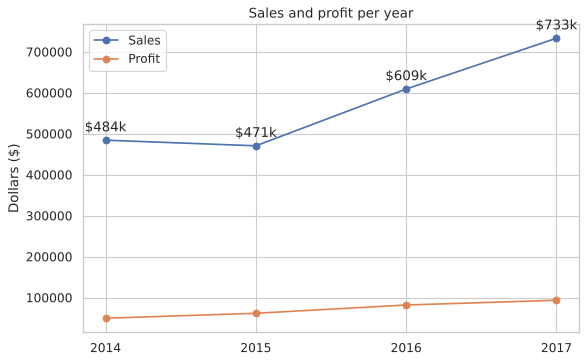

In [3]:
yearly = df.groupby("Year")[["Sales", "Profit"]].sum()  # total sales and profit for each year
print(yearly)  # show the numbers

fig, ax = plt.subplots(figsize=(8, 5))  # create a chart (fig = the picture, ax = the drawing area)
ax.plot(yearly.index, yearly["Sales"], marker="o", label="Sales")  # line for sales, with a dot for each year
ax.plot(yearly.index, yearly["Profit"], marker="o", label="Profit")  # line for profit
for year, value in yearly["Sales"].items():  # go through each year and its sales value
    ax.annotate(f"${value/1000:,.0f}k", (year, value), textcoords="offset points", xytext=(0, 8), ha="center")  # write the value above the dot
ax.set_xticks(yearly.index)  # show only whole years on the x axis
ax.set_title("Sales and profit per year")  # title
ax.set_ylabel("Dollars ($)")  # y label
ax.legend()  # show which line is which
plt.show()  # draw the chart

Top 4 months: [11, 12, 9, 3]
Share of sales in Sep-Dec: 51.6 %


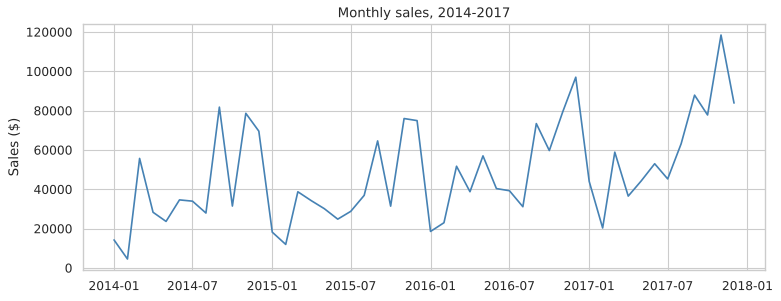

In [4]:
monthly = df.set_index("Order Date")["Sales"].resample("MS").sum()  # total sales for every month ("MS" = month start)

plt.figure(figsize=(11, 4))  # new empty chart, wide
plt.plot(monthly.index, monthly.values, color="steelblue")  # line of monthly sales over the 4 years
plt.title("Monthly sales, 2014-2017")  # title
plt.ylabel("Sales ($)")  # y label
plt.show()  # draw the chart

by_month = df.groupby("Month")["Sales"].sum()  # total sales per calendar month (all years together)
print("Top 4 months:", list(by_month.sort_values(ascending=False).head(4).index))  # which months sell the most
print("Share of sales in Sep-Dec:", round(by_month.loc[[9, 10, 11, 12]].sum() / by_month.sum() * 100, 1), "%")  # how much of the year is in the last 4 months

### Interactive version
The next cell turns the same chart into an **interactive** one: dropdown menus let you pick the region, the measure (sales or profit) and monthly or yearly view, and the Matplotlib chart redraws each time. It uses `ipywidgets`, which is already installed in Google Colab and normally in Jupyter (if not: `pip install ipywidgets`). It needs a live notebook, so the output is not saved here.

In [ ]:
from ipywidgets import interact  # interact turns a function into a chart with dropdown menus

regions = ["All"] + sorted(df["Region"].unique())  # the choices for the Region dropdown

def plot_trend(region="All", measure="Sales", frequency="Monthly"):  # this function redraws the chart for the chosen options
    data = df if region == "All" else df[df["Region"] == region]  # keep all rows, or only the chosen region
    rule = "MS" if frequency == "Monthly" else "YS"  # month-start or year-start grouping
    series = data.set_index("Order Date")[measure].resample(rule).sum()  # total of the chosen measure per month/year
    plt.figure(figsize=(10, 4))  # new empty chart
    plt.plot(series.index, series.values, marker="o")  # line with dots
    plt.title(f"{measure} per {frequency.lower()[:-2]}  ({region})")  # title that changes with the options
    plt.ylabel(f"{measure} ($)")  # y label
    plt.show()  # draw the chart

interact(plot_trend, region=regions, measure=["Sales", "Profit"], frequency=["Monthly", "Yearly"])  # create the dropdowns

**Insights from the trends:**
- Sales **dropped slightly in 2015 (-2.8%)**, then grew strongly: +29.5% in 2016 and +20.4% in 2017 (from $484k in 2014 to $733k in 2017).
- Profit grew even more: from about $49.5k in 2014 to $93.4k in 2017.
- There is a clear **seasonal pattern**: about **52% of the sales happen between September and December**, with November the biggest month and February the smallest.

## 3. Interactive map of sales

**Note about "by country":** this dataset only contains one country (the United States), so a map by country would have just one coloured area. Instead the map shows sales **by US state**, which is the useful version of the same idea.

Matplotlib on its own cannot draw maps with hover and zoom, so for this one I use **Plotly Express** (it is installed in Google Colab; otherwise `pip install plotly`). Hover over a state to see its sales, and zoom or drag the map. It needs a live notebook, so the output is not saved here.

In [ ]:
import plotly.express as px  # plotly express = quick interactive charts and maps

STATE_CODES = {  # plotly needs the 2-letter code of each state, so here is a lookup table (state name -> code)
    "Alabama": "AL", "Alaska": "AK", "Arizona": "AZ", "Arkansas": "AR", "California": "CA", "Colorado": "CO",
    "Connecticut": "CT", "Delaware": "DE", "District of Columbia": "DC", "Florida": "FL", "Georgia": "GA",
    "Hawaii": "HI", "Idaho": "ID", "Illinois": "IL", "Indiana": "IN", "Iowa": "IA", "Kansas": "KS",
    "Kentucky": "KY", "Louisiana": "LA", "Maine": "ME", "Maryland": "MD", "Massachusetts": "MA",
    "Michigan": "MI", "Minnesota": "MN", "Mississippi": "MS", "Missouri": "MO", "Montana": "MT",
    "Nebraska": "NE", "Nevada": "NV", "New Hampshire": "NH", "New Jersey": "NJ", "New Mexico": "NM",
    "New York": "NY", "North Carolina": "NC", "North Dakota": "ND", "Ohio": "OH", "Oklahoma": "OK",
    "Oregon": "OR", "Pennsylvania": "PA", "Rhode Island": "RI", "South Carolina": "SC", "South Dakota": "SD",
    "Tennessee": "TN", "Texas": "TX", "Utah": "UT", "Vermont": "VT", "Virginia": "VA", "Washington": "WA",
    "West Virginia": "WV", "Wisconsin": "WI", "Wyoming": "WY",
}

state_sales = df.groupby("State")[["Sales", "Profit"]].sum().reset_index()  # total sales and profit per state
state_sales["Code"] = state_sales["State"].map(STATE_CODES)  # add the 2-letter code column
print(state_sales["Code"].isna().sum(), "states without a code")  # should be 0

fig = px.choropleth(  # draw a map where each state is coloured by a value
    state_sales,  # the table to use
    locations="Code",  # which column holds the state codes
    locationmode="USA-states",  # tell plotly the codes are US states
    color="Sales",  # colour each state by its sales
    hover_name="State",  # show the state name when hovering
    hover_data={"Code": False, "Sales": ":,.0f", "Profit": ":,.0f"},  # show sales and profit in the hover box
    scope="usa",  # zoom the map to the USA
    color_continuous_scale="Blues",  # light to dark blue
    title="Sales by US state",  # title
)
fig.show()  # display the interactive map

**What the map shows:** sales are concentrated on the two coasts plus Texas. California, New York, Texas and Washington together make up about **47% of all sales**. Many states in the middle and north of the country have very small sales (North Dakota, South Dakota, Wyoming and Kansas are all under $3k). This matches the state ranking in the mini-project.

## 4. Seaborn: top 10 products and profit vs discount

Product Name
Canon imageCLASS 2200 Advanced Copier                                         61,600.0
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind   27,453.0
Cisco TelePresence System EX90 Videoconferencing Unit                         22,638.0
HON 5400 Series Task Chairs for Big and Tall                                  21,871.0
GBC DocuBind TL300 Electric Binding System                                    19,823.0
GBC Ibimaster 500 Manual ProClick Binding System                              19,024.0
Hewlett Packard LaserJet 3310 Copier                                          18,840.0
HP Designjet T520 Inkjet Large Format Printer - 24" Color                     18,375.0
GBC DocuBind P400 Electric Binding System                                     17,965.0
High Speed Automatic Electric Letter Opener                                   17,030.0
Name: Sales, dtype: float64


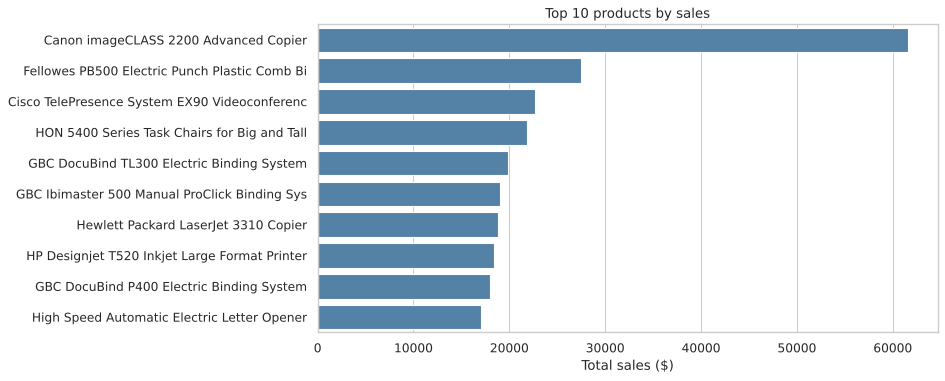

In [5]:
top_products = df.groupby("Product Name")["Sales"].sum().sort_values(ascending=False).head(10)  # total sales per product, keep the best 10
short_names = top_products.index.str[:45]  # cut long product names to 45 characters so they fit on the chart
print(top_products.round(0))  # show the numbers

plt.figure(figsize=(10, 5))  # new empty chart
sns.barplot(x=top_products.values, y=short_names, color="steelblue")  # horizontal bars: sales on x, product names on y
plt.title("Top 10 products by sales")  # title
plt.xlabel("Total sales ($)")  # x label
plt.ylabel("")  # no side label
plt.show()  # draw the chart

Correlation between discount and profit: -0.22
Order lines with discount >= 30%: 1393 | of them losing money: 96.8 %
Order lines with no discount: 4798 | of them losing money: 0.0 %
Total profit of the >=30% discount lines: -135376 | total profit overall: 286397


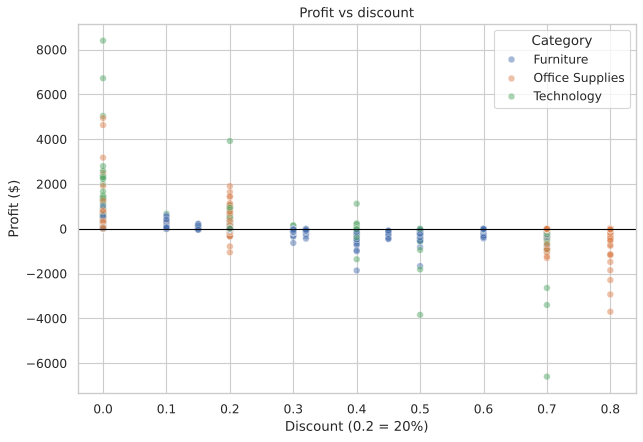

In [6]:
plt.figure(figsize=(9, 6))  # new empty chart
sns.scatterplot(data=df, x="Discount", y="Profit", hue="Category", alpha=0.5)  # one dot per order line; colour = product category; alpha makes dots see-through
plt.axhline(0, color="black", linewidth=1)  # a line at zero profit, so losses are easy to see below it
plt.title("Profit vs discount")  # title
plt.xlabel("Discount (0.2 = 20%)")  # x label
plt.ylabel("Profit ($)")  # y label
plt.show()  # draw the chart

print("Correlation between discount and profit:", round(df["Discount"].corr(df["Profit"]), 2))  # a number from -1 to 1 showing how they move together
high = df[df["Discount"] >= 0.3]  # only the order lines with a discount of 30% or more
print("Order lines with discount >= 30%:", len(high), "| of them losing money:", round((high["Profit"] < 0).mean() * 100, 1), "%")  # how many, and how many lose money
no_disc = df[df["Discount"] == 0]  # order lines with no discount at all
print("Order lines with no discount:", len(no_disc), "| of them losing money:", round((no_disc["Profit"] < 0).mean() * 100, 1), "%")  # do they ever lose money?
print("Total profit of the >=30% discount lines:", round(high["Profit"].sum()), "| total profit overall:", round(df["Profit"].sum()))  # the damage in dollars

**Insights from the Seaborn charts:**
- The best-selling product is the **Canon imageCLASS 2200 Advanced Copier** with about $61.6k, more than double the second one (a Fellowes binding machine, $27.5k). The top 10 is mostly office machines (copiers, binding machines, a printer) plus one video-conferencing system and one chair.
- **Discounts destroy profit.** The correlation between discount and profit is negative (-0.22). None of the order lines with no discount lost money, but almost all lines with a discount of 30% or more lost money, and together they lose about $135k, which is nearly half of the whole company's $286k profit.

## 5. Comparing Matplotlib and Seaborn

| | Matplotlib | Seaborn |
|---|---|---|
| **Ease of use** | More lines of code: I have to set up the figure, labels, ticks and annotations myself. | Very short: one line (`sns.barplot`, `sns.scatterplot`) gives a good-looking chart. |
| **Default look** | Plain; needs styling to look nice. | Clean and modern with `sns.set_theme`. |
| **Working with tables** | Works with lists/arrays, so I often have to prepare the numbers first. | Understands DataFrames directly (`data=df, x=..., y=...`) and can colour by a column (`hue="Category"`). |
| **Control** | Total control: annotations, several axes, any custom layout. | Less control by itself, but it is built on Matplotlib, so I can still use `plt.title`, `plt.axhline` etc. on top. |
| **Interactivity** | Static by default; interactive only with extra tools (`ipywidgets`, `%matplotlib widget`). | Static as well. |
| **Maps** | Not built in. | Not built in. I used Plotly for the map. |

**My observations:**
- Seaborn was faster and clearer for the **statistical** charts (the bar chart of top products and the scatter plot with colours by category).
- Matplotlib was better for the **custom** chart (the line chart with value labels on every year) and for adding extra lines on top of Seaborn charts.
- The best way is to use both together: Seaborn to draw the chart quickly, and Matplotlib to fine-tune it.
- For interactive hover/zoom (the map), neither one is enough, and a library like Plotly is a better choice.

## 6. Key insights summary
1. Sales and profit **grew strongly from 2016** (sales +29.5% in 2016 and +20.4% in 2017).
2. The year is **seasonal**: about half of the sales happen from September to December.
3. Sales are concentrated on the coasts and in Texas (California, New York, Texas and Washington are about 47% of all sales).
4. **Discounts of 30% or more almost always lose money**, and they wipe out nearly half of the profit. This is the most important finding for the business.
5. The top product (Canon copier) sells more than twice as much as the second one.